# Key findings so far

The findings behind the mid-report, each with its figure. Sections 1-6 are
the problem and what did not fix it; section 7 is what did. Every model score shown
here is either read from `experiments.jsonl` (the shared log) or re-computed
and checked against it, so the numbers here cannot drift from the log.

Scores are RMSE in dollars of monthly rent: 506 means a typical miss of about
$506 a month. Figures are also saved to `reports/figures/` for Overleaf.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import hdb_rentals as hr
from hdb_rentals import config
from hdb_rentals.baselines import RAW_FEATURES, model_matrix, score_horizon

# Chart colours: fixed order, so a series keeps its colour in every figure.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK_2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.figsize": (9, 4.2), "figure.dpi": 110,
    "font.family": "sans-serif", "font.size": 10,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
    "lines.linewidth": 2,
})

def save(fig, name):
    fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

train = hr.load_train()
log = pd.DataFrame(hr.read_log())
# The log is append-only, so a run can appear more than once; the newest wins.
latest = log.sort_values("timestamp").groupby(["name", "validation"]).tail(1).set_index(["name", "validation"])
monthly = train.groupby("APPROVAL_PERIOD")[config.TARGET].median()
print(f"{len(train):,} training rows, {monthly.index[0]} to {monthly.index[-1]}")

150,000 training rows, 2021-01 to 2025-03


## 1. Rent climbed until mid-2023, then went flat

The test months have no labels, so the model must forecast up to 16 months
past its last training month. A tree model cannot project a trend forward: it
predicts every test month at the March 2025 level (dashed line). That is right
if the flat stretch holds, and costly if the earlier climb comes back (dotted
line).

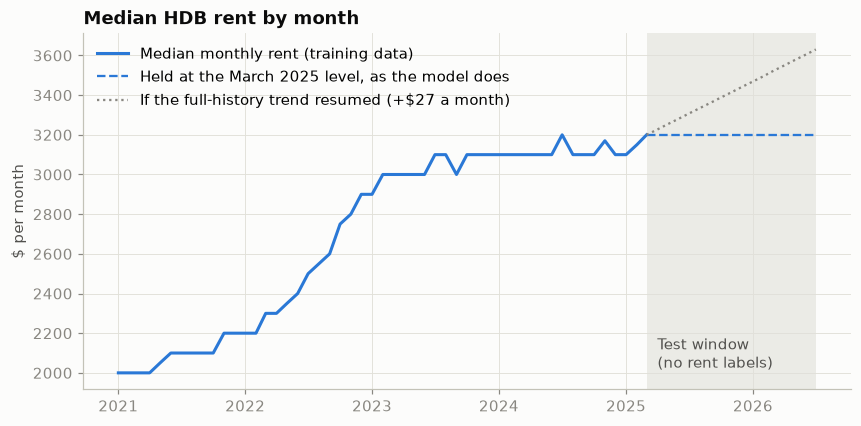

Full-history trend: +$26.9/month. Level in 2025-03: $3,200.


In [2]:
t = monthly.index.to_timestamp()
test_end = pd.Period(config.TEST_PERIOD[1], freq="M").to_timestamp()
future = pd.period_range(monthly.index[-1], config.TEST_PERIOD[1], freq="M").to_timestamp()

# Straight-line trend over every training row -- the same fit behind the
# report's "+$26.7 a month, $427 low" scenario -- restarted from the last level.
slope = np.polyfit(train["MONTH_INDEX"], train[config.TARGET], 1)[0]
last = monthly.iloc[-1]

fig, ax = plt.subplots()
ax.axvspan(future[0], test_end, color=GRID, alpha=0.6, lw=0)
ax.plot(t, monthly.to_numpy(), color=BLUE, label="Median monthly rent (training data)")
ax.plot(future, np.full(len(future), last), color=BLUE, ls="--", lw=1.5,
        label="Held at the March 2025 level, as the model does")
ax.plot(future, last + slope * np.arange(len(future)), color=MUTED, ls=":", lw=1.5,
        label=f"If the full-history trend resumed (+${slope:.0f} a month)")
ax.text(future[1], monthly.min(), "Test window\n(no rent labels)", color=INK_2, va="bottom")
ax.set_title("Median HDB rent by month")
ax.set_ylabel("$ per month")
ax.legend(loc="upper left")
save(fig, "01_rent_trend")
plt.show()
print(f"Full-history trend: +${slope:.1f}/month. Level in {monthly.index[-1]}: ${last:,.0f}.")

## 2. The further out, the more the model under-predicts

One training run on 2021-01..2023-11, scored on the next 16 months: the same
distance as the real test. RMSE barely moves, because later months have less
spread, but the under-prediction grows steadily. Watch the bias, not RMSE,
when judging the long horizon.

This cell re-runs the model and checks the result against the logged score.

16-month RMSE 506.18, matches the log (506.18)


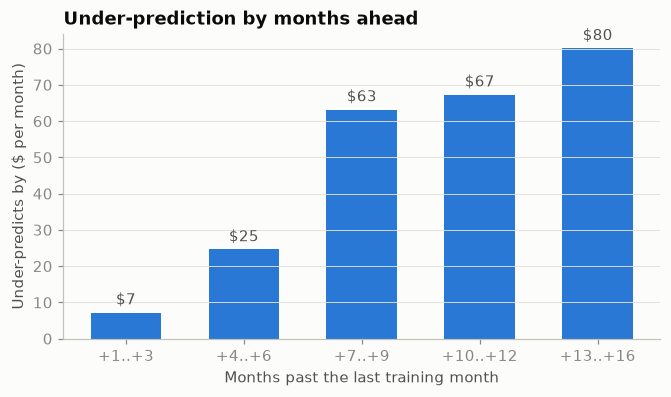

,horizon,n,target_sd,rmse,rmse_over_sd,bias
0,+1..+3,8829,687.6,544.7,0.792,-7.2
1,+4..+6,9347,683.8,526.1,0.769,-24.6
2,+7..+9,9089,682.6,506.2,0.742,-63.2
3,+10..+12,8086,637.6,480.1,0.753,-67.3
4,+13..+16,11820,644.7,476.7,0.740,-80.1


In [3]:
y = train[config.TARGET].to_numpy()
score, report = score_horizon(train, model_matrix(train, RAW_FEATURES), y)
logged = latest.loc[("lgbm-raw", "horizon-matched-16m"), "score"]
assert abs(score - logged) < 0.01, f"re-run {score:.2f} does not match log {logged:.2f}"
print(f"16-month RMSE {score:.2f}, matches the log ({logged:.2f})")

fig, ax = plt.subplots(figsize=(7, 3.6))
under = -report["bias"]
bars = ax.bar(report["horizon"], under, color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"${v:.0f}" for v in under], padding=3, color=INK_2)
ax.set_title("Under-prediction by months ahead")
ax.set_xlabel("Months past the last training month")
ax.set_ylabel("Under-predicts by ($ per month)")
ax.grid(axis="x", visible=False)
save(fig, "02_horizon_bias")
plt.show()
report

## 3. Which window you score on moves RMSE more than most features will

Five walk-forward rehearsals of the same model. Early 2024 is harder to
predict than late 2024, and that alone swings RMSE by about $82. Compare a new
feature against these five folds one by one, not mean against mean.

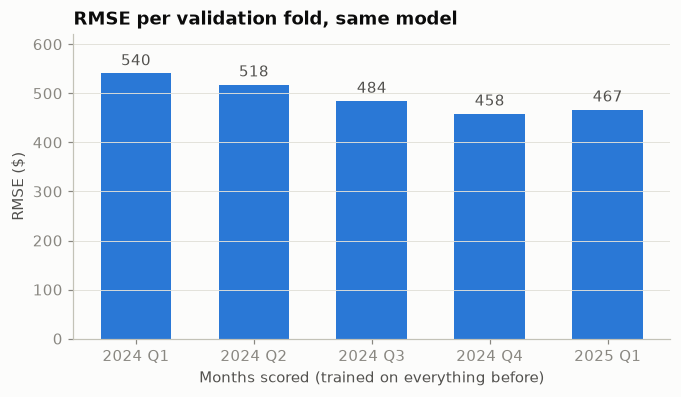

Spread between folds: 82; mean 493.4


In [4]:
folds = latest.loc[("lgbm-raw", "expanding-window-5x3"), "fold_scores"]
labels = ["2024 Q1", "2024 Q2", "2024 Q3", "2024 Q4", "2025 Q1"]

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(labels, folds, color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"{v:.0f}" for v in folds], padding=3, color=INK_2)
ax.set_ylim(0, max(folds) * 1.15)
ax.set_title("RMSE per validation fold, same model")
ax.set_xlabel("Months scored (trained on everything before)")
ax.set_ylabel("RMSE ($)")
ax.grid(axis="x", visible=False)
save(fig, "03_fold_scores")
plt.show()
print(f"Spread between folds: {max(folds) - min(folds):.0f}; mean {np.mean(folds):.1f}")

## 4. Swapping the month counter for COE or share prices does not help

Same model each time; only the time feature changes. Nothing beats the month
counter by a meaningful margin, and a boat builder's share price (the
placebo, picked for having no link to rent) matches the best macro arm. Any
series that rose with rent in 2021-23 buys that much.

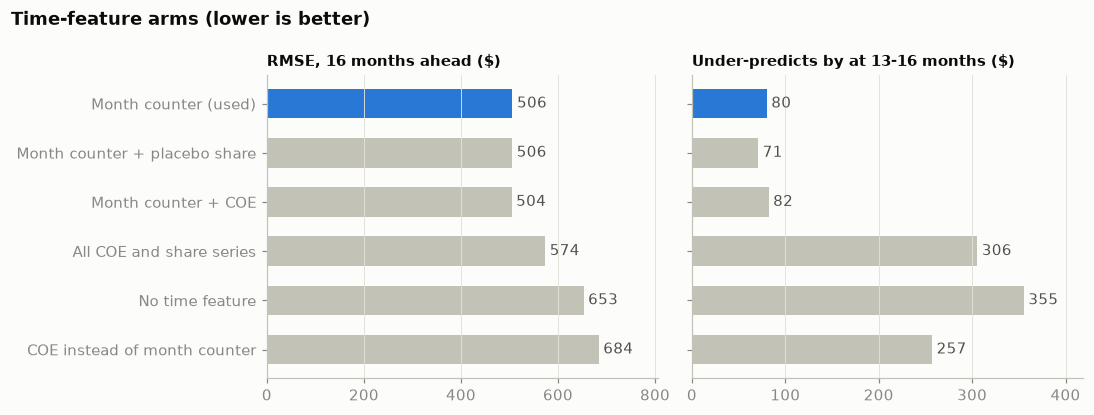

In [5]:
arms = [
    ("lgbm-raw", "Month counter (used)"),
    ("placebo-penguin", "Month counter + placebo share"),
    ("lgbm-macro-plus-time", "Month counter + COE"),
    ("lgbm-macro-ungated", "All COE and share series"),
    ("lgbm-no-time", "No time feature"),
    ("lgbm-macro-only", "COE instead of month counter"),
]
rows = latest.xs("horizon-matched-16m", level="validation").loc[[a for a, _ in arms]]
bias = rows["notes"].str.extract(r"Bias[^:]*:\s*(-?\d+(?:\.\d+)?)")[0].astype(float)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
names = [label for _, label in arms][::-1]
colors = [BLUE if a == "lgbm-raw" else AXIS for a, _ in arms][::-1]
for ax, values, title in [
    (a1, rows["score"].to_numpy()[::-1], "RMSE, 16 months ahead ($)"),
    (a2, -bias.to_numpy()[::-1], "Under-predicts by at 13-16 months ($)"),
]:
    bars = ax.barh(names, values, color=colors, height=0.6)
    ax.bar_label(bars, labels=[f"{v:.0f}" for v in values], padding=3, color=INK_2)
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, max(values) * 1.18)
fig.suptitle("Time-feature arms (lower is better)", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "04_time_feature_arms")
plt.show()

## 5. Why COE fails: one COE level, two different rents

COE rose with rent until its 2023-09 peak, then fell while rent stayed flat.
So a COE price of about $100k shows up both in the cheap-rent early period and
in the flat, high-rent period, and the model cannot tell which one it is in.

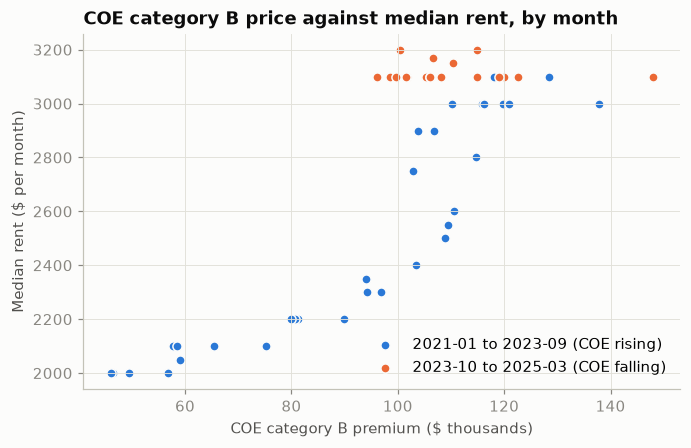

In [6]:
macro = hr.load_macro(gate=False)
coe = macro["COE_B"]
coe.index = pd.period_range("2021-01", periods=len(coe), freq="M")
both = pd.concat([coe.rename("coe"), monthly.rename("rent")], axis=1).dropna()
rising = both.loc[:"2023-09"]
falling = both.loc["2023-10":]

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(rising["coe"] / 1000, rising["rent"], s=36, color=BLUE,
           edgecolor=SURFACE, lw=1, label="2021-01 to 2023-09 (COE rising)")
ax.scatter(falling["coe"] / 1000, falling["rent"], s=36, color=ORANGE,
           edgecolor=SURFACE, lw=1, label="2023-10 to 2025-03 (COE falling)")
ax.set_title("COE category B price against median rent, by month")
ax.set_xlabel("COE category B premium ($ thousands)")
ax.set_ylabel("Median rent ($ per month)")
ax.legend(loc="lower right")
save(fig, "05_coe_two_regimes")
plt.show()

## 6. Housing-related shares move against rent, for reasons unrelated to rent

All four series are indexed to 100 in January 2021 so they share one scale.
In 2022 rising interest rates pulled REITs down while the flat shortage pushed
rent up, so REITs look inversely linked to rent. REITs then recover in the test
window, which a model would read as rent falling. Developer and bank shares
climb far past anything seen in training, where a tree model stops responding.
Singapore REITs own offices, malls, warehouses and hotels, not rental flats.
The stock search is closed.

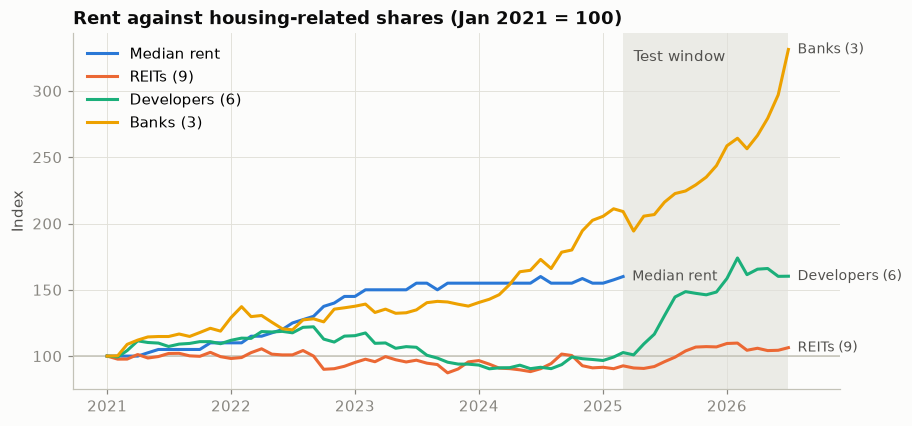

,moves with rent (-1..+1),test months inside training range
REITs (9),-0.69,0.56
Developers (6),-0.56,0.19
Banks (3),0.74,0.19


In [7]:
st = pd.read_csv(config.AUX_CSV["stocks"], parse_dates=["DATE"])
st["period"] = st["DATE"].dt.to_period("M")
px = st.pivot_table(index="period", columns="NAME", values="ADJUSTED_CLOSE", aggfunc="mean")
px = px.loc[config.TRAIN_PERIOD[0]:config.TEST_PERIOD[1]]

groups = {
    "REITs (9)": ["Ascendas Reit", "CapitaLand Ascott Trust", "CapitaLand Mall Trust",
                  "Frasers Logistics & Industrial Trust", "Keppel REIT",
                  "Mapletree Commercial Trust", "Mapletree Industrial Trust",
                  "Mapletree Logistics Trust", "Suntec REIT"],
    "Developers (6)": ["City Developments", "UOL Group", "Singapore Land",
                       "Hotel Properties Limited", "Yanlord",
                       "Pacific Century Regional Developments"],
    "Banks (3)": ["DBS Group", "OCBC Bank", "UOB"],
}
idx = pd.DataFrame({k: (px[v] / px[v].iloc[0] * 100).mean(axis=1) for k, v in groups.items()})
idx.insert(0, "Median rent", monthly / monthly.iloc[0] * 100)

fig, ax = plt.subplots()
ax.axvspan(future[0], test_end, color=GRID, alpha=0.6, lw=0)
ax.axhline(100, color=AXIS, lw=1)
for (name, s), color in zip(idx.items(), [BLUE, ORANGE, AQUA, YELLOW]):
    s = s.dropna()
    ax.plot(s.index.to_timestamp(), s.to_numpy(), color=color, label=name)
    ax.annotate(name, (s.index[-1].to_timestamp(), s.iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK_2, fontsize=9)
ax.text(future[1], idx.max().max(), "Test window", color=INK_2, va="top")
ax.set_title("Rent against housing-related shares (Jan 2021 = 100)")
ax.set_ylabel("Index")
ax.set_xlim(right=test_end + pd.DateOffset(months=5))
ax.legend(loc="upper left")
save(fig, "06_property_shares")
plt.show()

trn, tst = idx.loc[:config.TRAIN_PERIOD[1]], idx.loc[pd.Period(config.TRAIN_PERIOD[1], "M") + 1:]
pd.DataFrame({
    "moves with rent (-1..+1)": trn.corr()["Median rent"].drop("Median rent").round(2),
    "test months inside training range": (
        (tst >= trn.min()) & (tst <= trn.max())).drop(columns="Median rent").mean().round(2),
})

## 7. Forecasting the market level instead of freezing it

Section 1 showed the problem: the model repeats the March 2025 level for every
test month. The fix splits every rent into two parts that behave differently:

**rent = market level (this month) x premium (this flat)**

- The **market level** is what a typical flat rents for in a given month. One
  number per month, and it is the only part that moves over time.
- The **premium** is how much pricier this particular flat is than a typical
  one. It barely changes over the years, so what the model learns from 2021-23
  still applies in 2025.

The two parts are learned separately, in three steps (`hdb_rentals.market_level`).

### 7.1 Step 1: the market level, from a regression

One equation is fitted to all 150,000 training rows by ordinary least squares:

    log(rent) = constant + month effect + town effect + flat type effect
              + flat model effect + b1 x floor area + b2 x flat age

Because town, type, size and age each get their own term, the **month effect**
captures only what is left: how much higher rent is that month than in
January 2021 *for the same kind of flat*. A month where more big flats happened
to rent does not inflate it -- floor area absorbs that.

The equation uses the log of rent so that a month effect is a percentage: an
effect of 0.34 means e^0.34 = 1.40, i.e. rents 40% above January 2021 for every
flat alike. Only the month effects are kept; the rest of the equation is
discarded.

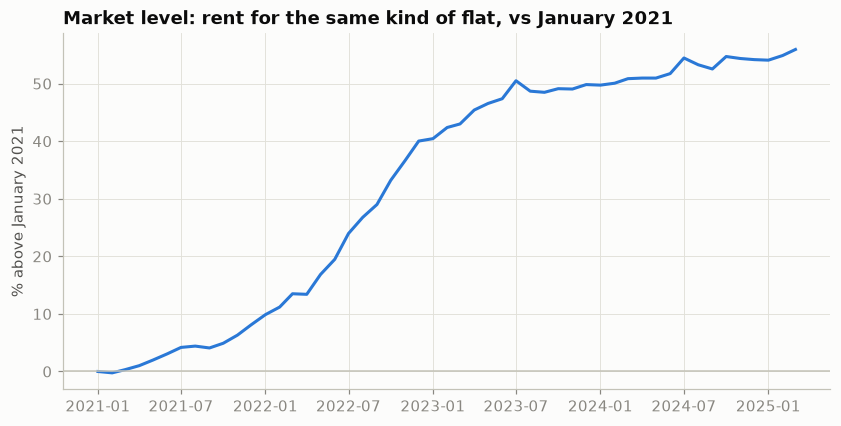

,month,month effect,vs Jan 2021
0,2021-01,0.000,+0.0%
1,2022-01,0.094,+9.9%
2,2023-01,0.340,+40.4%
3,2023-07,0.409,+50.5%
4,2024-01,0.404,+49.7%
5,2025-03,0.444,+55.9%


In [8]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from hdb_rentals.market_level import forecast_level, hedonic_level

def pct(log_level):
    return 100 * (np.exp(log_level) - 1)

level = hedonic_level(train, np.arange(len(train)))
level_t = pd.period_range("2021-01", periods=len(level), freq="M").to_timestamp()

fig, ax = plt.subplots()
ax.plot(level_t, pct(level.to_numpy()), color=BLUE)
ax.axhline(0, color=AXIS, lw=1)
ax.set_title("Market level: rent for the same kind of flat, vs January 2021")
ax.set_ylabel("% above January 2021")
save(fig, "07_market_level")
plt.show()

pd.DataFrame({
    "month": [str(pd.Period("2021-01", "M") + m) for m in [0, 12, 24, 30, 36, 50]],
    "month effect": level.loc[[0, 12, 24, 30, 36, 50]].round(3).to_numpy(),
    "vs Jan 2021": [f"{v:+.1f}%" for v in pct(level.loc[[0, 12, 24, 30, 36, 50]])],
})

### 7.2 Step 2: the premium, from the tree

Each training rent is divided by its month's market level. That turns it into
**what the flat would have rented for in the January 2021 market**. The tree
(LightGBM) learns to predict this adjusted rent from town, flat type, flat
model, floor area and flat age -- and never sees the month, because the
market's rise has already been taken out.

The table shows why this works. Queenstown 3-room flats rose by over $1,000 a
month in raw rent, but once each month's market level is divided out, the
adjusted rent barely moves. That stable number is what the tree learns.

**To predict:** tree output x forecast market level for that month.

In [9]:
example = train[(train["TOWN"] == "queenstown") & (train["FLAT_TYPE"] == "3-room")]
months = [0, 12, 24, 36, 50]
raw = example.groupby("MONTH_INDEX")[config.TARGET].median().loc[months]
pd.DataFrame({
    "month": [str(pd.Period("2021-01", "M") + m) for m in months],
    "median rent": raw.to_numpy().round(0),
    "market level": np.exp(level.loc[months]).round(3).to_numpy(),
    "adjusted to Jan 2021 market": (raw / np.exp(level.loc[months])).round(0).to_numpy(),
})

,month,median rent,market level,adjusted to Jan 2021 market
0,2021-01,1900.0,1.000,1900.0
1,2022-01,2200.0,1.099,2002.0
2,2023-01,2750.0,1.404,1958.0
3,2024-01,3000.0,1.497,2003.0
4,2025-03,3000.0,1.559,1924.0


### 7.3 Step 3: forecasting the level with a damped trend

The month effects form a 51-point series. A damped trend forecasts it using two
running figures, updated month by month:

- **level** -- its smoothed estimate of where the market is now
- **trend** -- its smoothed estimate of how fast the market is moving per month

Each month it compares its forecast with what happened and nudges both figures
toward the actual value. Three settings control how, chosen automatically as
the values that would best have predicted each next month over training:

- **alpha** -- how strongly the level follows the latest month
- **beta** -- how quickly the trend changes its mind
- **phi** -- the damping: each future month's step is phi times the previous
  one, so the forecast bends toward flat instead of rising forever

For comparison, *hold* keeps the level flat, and a *straight line* continues
the average slope of all training months -- which includes the steep 2021-23
climb.

,setting,fitted value
0,alpha (level),0.85
1,beta (trend),0.41
2,phi (damping),0.961
3,trend at 2025-03,+0.37% a month


,months ahead,forecast rise that month
0,1,+0.36%
1,2,+0.34%
2,4,+0.32%
3,8,+0.27%
4,16,+0.20%


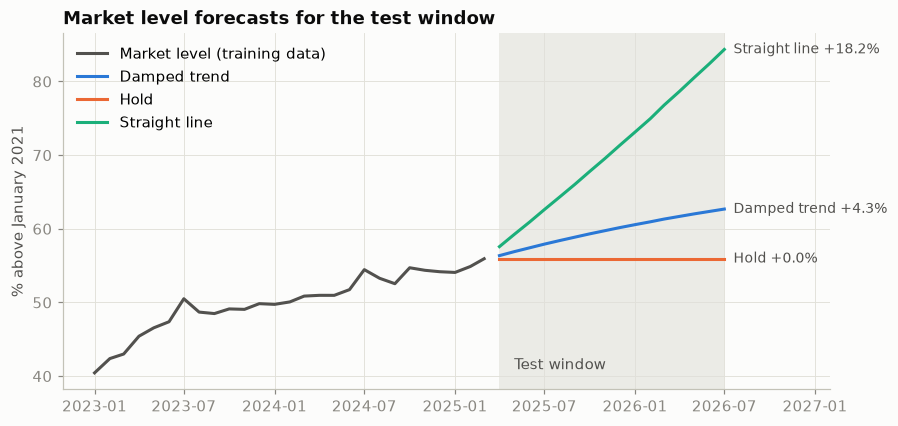

Damped steps add up to at most +9.6% however far out it forecasts.


In [10]:
fit = ExponentialSmoothing(level.to_numpy(), trend="add", damped_trend=True,
                           initialization_method="estimated").fit()
alpha, beta, phi = (fit.params[k] for k in ("smoothing_level", "smoothing_trend", "damping_trend"))
trend_now = fit.trend[-1]
steps = np.diff(np.r_[fit.level[-1], fit.forecast(16)])

display(pd.DataFrame({
    "setting": ["alpha (level)", "beta (trend)", "phi (damping)", "trend at 2025-03"],
    "fitted value": [f"{alpha:.2f}", f"{beta:.2f}", f"{phi:.3f}", f"{pct(trend_now):+.2f}% a month"],
}))
display(pd.DataFrame({
    "months ahead": [1, 2, 4, 8, 16],
    "forecast rise that month": [f"{pct(steps[h - 1]):+.2f}%" for h in [1, 2, 4, 8, 16]],
}))

test_months = np.arange(len(level), len(level) + 16)
ahead_t = pd.period_range("2025-04", periods=16, freq="M").to_timestamp()
recent = level.loc[24:]

fig, ax = plt.subplots()
ax.axvspan(ahead_t[0], ahead_t[-1], color=GRID, alpha=0.6, lw=0)
ax.plot(level_t[24:], pct(recent.to_numpy()), color=INK_2, label="Market level (training data)")
for method, color, label in [("damped", BLUE, "Damped trend"), ("hold", ORANGE, "Hold"),
                             ("linear", AQUA, "Straight line")]:
    f = forecast_level(level, test_months, method).loc[test_months]
    ax.plot(ahead_t, pct(f.to_numpy()), color=color, label=label)
    ax.annotate(f"{label} {pct(f.iloc[-1] - level.iloc[-1]):+.1f}%", (ahead_t[-1], pct(f.iloc[-1])),
                xytext=(6, 0), textcoords="offset points", va="center", color=INK_2, fontsize=9)
ax.text(ahead_t[1], pct(recent.min()), "Test window", color=INK_2, va="bottom")
ax.set_title("Market level forecasts for the test window")
ax.set_ylabel("% above January 2021")
ax.set_xlim(right=ahead_t[-1] + pd.DateOffset(months=7))
ax.legend(loc="upper left")
save(fig, "08_level_forecasts")
plt.show()
print(f"Damped steps add up to at most {pct(trend_now * phi / (1 - phi)):+.1f}% however far out it forecasts.")

### 7.4 Does it work? Two forecast origins

Each arm is scored on a 16-month fold, the same distance as the real test, from
two starting points with opposite market conditions:

- **flat origin:** train to 2023-11, score 2023-12 to 2025-03 (market flat)
- **climb origin:** train to 2022-06, score 2022-07 to 2023-10 (market climbing)

The figure shows the climb origin: each method's level forecast from June 2022
against the level that actually happened.

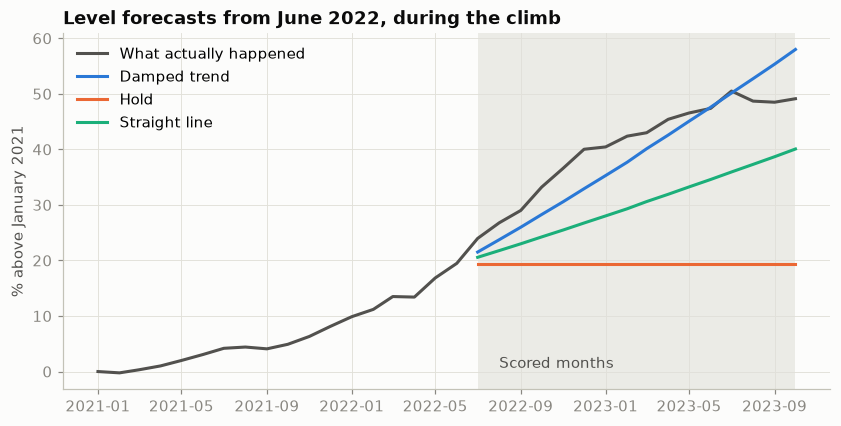

In [11]:
climb = train[train["MONTH_INDEX"] <= 33].reset_index(drop=True)
climb_trn = np.flatnonzero(climb["MONTH_INDEX"] <= 17)
fitted = hedonic_level(climb, climb_trn)
future_m = np.arange(18, 34)
future_t = pd.period_range("2022-07", periods=16, freq="M").to_timestamp()

fig, ax = plt.subplots()
ax.axvspan(future_t[0], future_t[-1], color=GRID, alpha=0.6, lw=0)
ax.plot(level_t[:34], pct(level.loc[:33].to_numpy()), color=INK_2, label="What actually happened")
for method, color, label in [("damped", BLUE, "Damped trend"), ("hold", ORANGE, "Hold"),
                             ("linear", AQUA, "Straight line")]:
    f = forecast_level(fitted, future_m, method).loc[future_m]
    ax.plot(future_t, pct(f.to_numpy()), color=color, label=label)
ax.text(future_t[1], 0, "Scored months", color=INK_2, va="bottom")
ax.set_title("Level forecasts from June 2022, during the climb")
ax.set_ylabel("% above January 2021")
ax.legend(loc="upper left")
save(fig, "09_climb_origin")
plt.show()

### 7.5 Scores at both origins

Every arm uses the same tree for the premium; they differ only in the level.
The **oracle** uses the actual level of the scored months -- it cheats, so it is
not usable, but it shows how good the model would be with a perfect level
forecast. It still has error because RMSE scores each flat, and two flats the
tree cannot tell apart can rent hundreds of dollars apart.

So each arm's RMSE reads as **oracle + the cost of getting the level wrong**.
When the market is flat, level mistakes barely matter. When it climbs, holding
flat costs about $180 of RMSE and the damped trend cuts that to about $9. Its
weak spot shows at the end of the climb window: it overshoots by about $87
while its trend figure catches up with the mid-2023 flattening.

Scores are read from `experiments.jsonl`. The two origins score different
months, so compare arms within a column, not across.

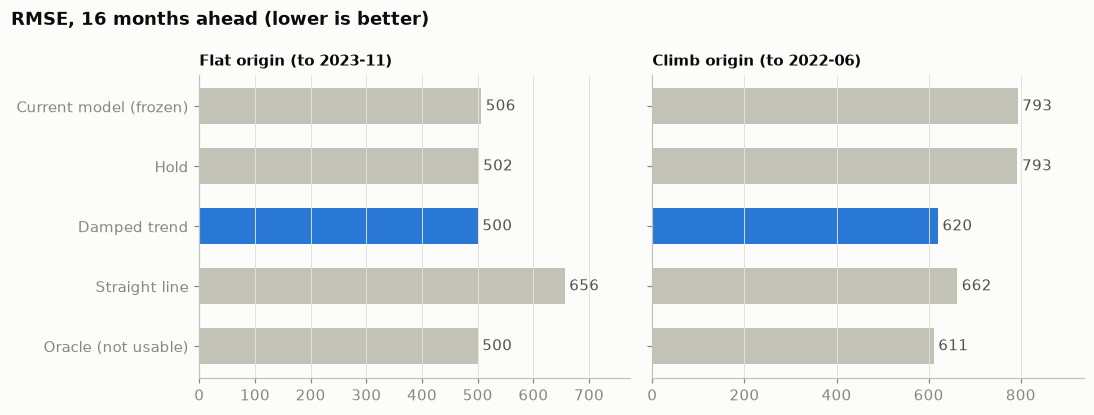

Flat origin (to 2023-11)              \
                                           RMSE over oracle   
name                                                          
Current model (frozen)                   506.18         6.3   
Hold                                     501.55         1.7   
Damped trend                             500.11         0.2   
Straight line                            656.20       156.3   
Oracle (not usable)                      499.90         0.0   

                                            Climb origin (to 2022-06)  \
                       bias at 13-16 months                      RMSE   
name                                                                    
Current model (frozen)                -80.1                    793.34   
Hold                                  -73.9                    792.79   
Damped trend                          -49.9                    620.01   
Straight line                         651.8                    661.91   
Oracle (not usable)                    41.2                    610.99   

                                                         
                       over oracle bias at 13-16 months  
name                                                     
Current model (frozen)       182.3               -619.6  
Hold                         181.8               -624.2  
Damped trend                   9.0                 86.5  
Straight line                 50.9               -242.5  
Oracle (not usable)            0.0                -12.5

In [12]:
origins = {"Flat origin (to 2023-11)": "horizon-matched-16m",
           "Climb origin (to 2022-06)": "horizon-16m-origin-2022-06"}
arm_labels = {"lgbm-raw": "Current model (frozen)", "level-hold": "Hold",
              "level-damped": "Damped trend", "level-linear": "Straight line",
              "level-oracle": "Oracle (not usable)"}

table = {}
for title, validation in origins.items():
    rows = latest.xs(validation, level="validation").loc[list(arm_labels)]
    oracle = rows.loc["level-oracle", "score"]
    table[(title, "RMSE")] = rows["score"].round(2)
    table[(title, "over oracle")] = (rows["score"] - oracle).round(1)
    table[(title, "bias at 13-16 months")] = (
        rows["notes"].str.extract(r"Bias[^:]*:\s*(-?\d+(?:\.\d+)?)")[0].astype(float))
scores = pd.DataFrame(table).rename(index=arm_labels)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
names = list(arm_labels.values())[::-1]
colors = [BLUE if n == "Damped trend" else AXIS for n in names]
for ax, title in zip(axes, origins):
    values = scores.loc[names, (title, "RMSE")].to_numpy()
    bars = ax.barh(names, values, color=colors, height=0.6)
    ax.bar_label(bars, labels=[f"{v:.0f}" for v in values], padding=3, color=INK_2)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, max(values) * 1.18)
    ax.grid(axis="y", visible=False)
fig.suptitle("RMSE, 16 months ahead (lower is better)", x=0.01, ha="left",
             fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "10_level_arms")
plt.show()
scores